# Reimplements Experiment 3 (Exp3_f0s2) of Polonenko, 2026

In [1]:
from pathlib import Path
import subprocess

repo_dir = Path("/content/ABR-Deconv")
if not repo_dir.exists():
    subprocess.run(
        ["git", "clone",
         "https://github.com/jduantc/ABR-Deconv.git",
         str(repo_dir)],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(repo_dir), "pull", "--ff-only"],
        check=True,
    )

%pip -q install -r /content/ABR-Deconv/prelim_exp3/requirements.txt

In [2]:
import sys
import importlib
import numpy as np
import matplotlib.pyplot as plt

# from scipy.fft import next_fast_len
from scipy.signal import butter, sosfiltfilt

sys.path.insert(0, str(repo_dir))

from prelim_exp3 import analysis, metrics
importlib.reload(analysis)
importlib.reload(metrics)

# if not hasattr(analysis.mne.filter, "next_fast_len"):
#     analysis.mne.filter.next_fast_len = next_fast_len

<module 'prelim_exp3.metrics' from '/content/ABR-Deconv/prelim_exp3/metrics.py'>

In [3]:
import requests
from tqdm.auto import tqdm

data_dir = Path("/content/abr_data")
base_url = "https://data.nemar.org/on008065/v1.0.0"

subjects = ["sub-exp303"] #["sub-exp301", "sub-exp302", "sub-exp303"]
run = "01"

stories = ["wizard", "wonderland", "drdolittle"]
story_index = 0
max_trials = 2
alphas = [10, 100, 1000, 10000]

bands_khz = [0.5, 1, 2, 4, 8]
ears = ["left", "right"]

def download_file(relative_path):
    destination = data_dir / relative_path

    if destination.exists():
        return destination

    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + ".part")

    with requests.get(
        f"{base_url}/{relative_path}",
        stream=True,
        timeout=(30, 300),
    ) as response:
        response.raise_for_status()

        with temporary.open("wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    temporary.replace(destination)
    return destination

# Download and load one EEG run

In [4]:
def stimulus_relative_path(story_id, token_id):
    story = stories[story_id]
    return (
        f"stimuli/exp3_f0s2/{story}/"
        f"{story}_shifted_{token_id + 1:04d}.hdf5"
    )

def stimulus_path(story_id, token_id):
    return data_dir / stimulus_relative_path(story_id, token_id)

def process_participant(subject):
  print(f"Processing {subject}")
  # download and load one EEG run
  stem = f"{subject}_task-f0s2_run-{run}"
  eeg_relative_dir = f"{subject}/eeg"

  for extension in ["vhdr", "vmrk", "eeg"]:
      print(f"Downloading/checking {extension}")
      download_file(
          f"{eeg_relative_dir}/{stem}_eeg.{extension}"
      )

  events_path = download_file(
      f"{eeg_relative_dir}/{stem}_events.tsv"
  )

  vhdr_path = data_dir / eeg_relative_dir / f"{stem}_eeg.vhdr"

  raw, events = analysis.load_eeg(
      vhdr_path,
      events_path,
      preload=True,
  )

  # process EEG / decode markers / select trials
  eeg, fs_eeg = analysis.process_eeg(raw)

  stim_events, clock_adjust = analysis.decode_events(
      events,
      fs_eeg,
  )

  trials = analysis.select_trials(
      stim_events,
      story_index=story_index,
      max_trials=max_trials,
  )

  epochs, retained_trials = analysis.extract_epochs(
      eeg,
      trials,
      fs_eeg,
      first_sample=raw.first_samp,
  )

  print("Clock adjustment:", clock_adjust)
  print("Selected trials:", len(trials))
  print("Retained trials:", len(retained_trials))
  print("EEG epochs:", epochs.shape)
  print("First retained rows:")
  print(retained_trials[:5])

  # The epochs are copies, so the continuous arrays can be deleted
  del eeg, raw

  # download stimulus files
  needed = sorted({
      (int(story), int(token))
      for _, token, story in retained_trials
  })

  for story_id, token_id in tqdm(needed, desc="Stimulus files"):
      download_file(stimulus_relative_path(story_id, token_id))

  # Inspect one file before constructing the pulse trains
  _, first_token, first_story = retained_trials[0]

  stimulus_data = analysis.read_hdf5(
      stimulus_path(int(first_story), int(first_token))
  )

  print("Stimulus keys:", list(stimulus_data))

  # construct pulse trains

  if {"pulseinds_true", "pulseinds_fake"} <= stimulus_data.keys():
      true_key = "pulseinds_true"
      fake_key = "pulseinds_fake"
  elif {"pulse_inds", "fake_pulse_inds"} <= stimulus_data.keys():
      true_key = "pulse_inds"
      fake_key = "fake_pulse_inds"
  else:
      raise KeyError("Could not identify the stimulus pulse-index keys.")

  c, cf = analysis.build_pulse_trains(
      retained_trials,
      stimulus_path,
      fs_eeg,
      clock_adjust,
      true_key=true_key,
      fake_key=fake_key,
  )

  y = epochs[:, None, None, :, :]

  print("Real pulses:", c.shape)
  print("Sham pulses:", cf.shape)
  print("EEG:", y.shape)

  assert c.shape[0] == cf.shape[0] == y.shape[0]
  assert c.shape[-1] == cf.shape[-1] == y.shape[-1]

  # Original method.
  x_isol, x_combined = analysis.deconv(c, cf, y)

  variants = {
      "Original": {
          "bands": x_isol,
          "combined": x_combined,
      }
  }

  # All methods use the same c, cf, y.
  for alpha in alphas:
      print(f"{subject}: Wiener alpha={alpha}")

      bands, combined = analysis.deconv_wiener(
          c, cf, y, alpha=alpha,
      )

      variants[f"Wiener α={alpha:g}"] = {
          "bands": bands,
          "combined": combined,
      }

  for name, variant in variants.items():
      assert np.isfinite(variant["bands"]).all(), name
      assert np.isfinite(variant["combined"]).all(), name

  del c, cf, y, epochs

  return {
      "subject": subject,
      "fs": fs_eeg,
      "n_trials": len(retained_trials),
      "x_isol": x_isol,
      "x_combined": x_combined,
      "variants": variants,
  }


In [5]:
results = []

for subject in subjects:
    print(f"Processing {subject}")
    results.append(process_participant(subject))

Processing sub-exp303
Processing sub-exp303
Downloading/checking vhdr
Downloading/checking vmrk
Downloading/checking eeg
Extracting parameters from /content/abr_data/sub-exp303/eeg/sub-exp303_task-f0s2_run-01_eeg.vhdr...
Setting channel info structure...
Reading 0 ... 31808199  =      0.000 ...  3180.820 secs...
Used Annotations descriptions: ['Stimulus/S  1', 'Stimulus/S  2', 'Stimulus/S  4', 'Stimulus/S  8']
Clock adjustment: 0.9999907210847981
Selected trials: 2
Retained trials: 2
EEG epochs: (2, 2, 120000)
First retained rows:
[[356373      0      0]
 [660589      1      0]]


Stimulus files:   0%|          | 0/2 [00:00<?, ?it/s]

Stimulus keys: ['fs', 'pulseinds_fake', 'pulseinds_true', 'x_play_band_chirp_CE']
Real pulses: (2, 2, 5, 1, 120000)
Sham pulses: (2, 1, 5, 1, 120000)
EEG: (2, 1, 1, 2, 120000)
sub-exp303: Wiener alpha=10
sub-exp303: Wiener alpha=100
sub-exp303: Wiener alpha=1000
sub-exp303: Wiener alpha=10000


In [6]:
# completed = {result["subject"] for result in results}

# for subject in subjects:
#     if subject in completed:
#         print(f"Already completed: {subject}")
#         continue

#     print(f"Processing {subject}")
#     results.append(process_participant(subject))

# Additional filtering after Deconv
(Same setup as original experiment)

In [6]:
import pandas as pd
from scipy.signal import butter, lfilter

rows = []

for result in results:
    fs_eeg = result["fs"]
    duration_seconds = result["n_trials"] * 10.0

    b_post, a_post = butter(
        1, 150, btype="highpass", fs=fs_eeg,
    )

    for name, variant in result["variants"].items():
        variant["band_curves"] = lfilter(
            b_post, a_post, variant["bands"], axis=-1,
        )
        variant["combined_curves"] = lfilter(
            b_post, a_post, variant["combined"], axis=-1,
        )

        for prefix, waveform in [
            ("band", variant["band_curves"]),
            ("combined", variant["combined_curves"]),
        ]:
            _, snr, t0 = metrics.get_snr(
                waveform,
                fs=fs_eeg,
                n_pre=analysis.n_pre,
                dur_secs=duration_seconds,
            )

            variant[f"{prefix}_snr"] = snr
            variant[f"{prefix}_t0"] = t0

        for ear, ear_name in enumerate(ears):
            for band, frequency in enumerate(bands_khz):
                snr = variant["band_snr"][ear, band]
                rows.append({
                    "subject": result["subject"],
                    "ear": ear_name,
                    "band_khz": frequency,
                    "method": name,
                    "snr_db": snr,
                    "t0_min": variant["band_t0"][ear, band] / 60,
                    "floor_limited": snr <= -20,
                })

comparison = pd.DataFrame(rows)

display(
    comparison.pivot(
        index=["subject", "ear", "band_khz"],
        columns="method",
        values=["snr_db", "t0_min"],
    ).round(2)
)

snr_db                                         \
method                    Original Wiener α=10 Wiener α=100 Wiener α=1000   
subject    ear   band_khz                                                   
sub-exp303 left  0.5         -6.59       -6.57        -6.50         -6.76   
                 1.0         -6.97       -6.96        -6.83         -5.76   
                 2.0          1.17        1.19         1.27          1.55   
                 4.0         -5.75       -5.73        -5.61         -4.80   
                 8.0         -7.59       -7.56        -7.31         -6.05   
           right 0.5        -20.00      -20.00       -20.00        -20.00   
                 1.0        -20.00      -20.00       -20.00        -20.00   
                 2.0         -2.39       -2.37        -2.32         -2.05   
                 4.0        -20.00      -20.00       -20.00        -13.09   
                 8.0         -8.50       -8.57        -9.11        -17.64   

                                           t0_min                           \
method                    Wiener α=10000 Original Wiener α=10 Wiener α=100   
subject    ear   band_khz                                                    
sub-exp303 left  0.5              -11.43     1.52        1.51         1.49   
                 1.0               -3.79     1.66        1.66         1.61   
                 2.0                2.44     0.25        0.25         0.25   
                 4.0               -2.94     1.25        1.25         1.21   
                 8.0               -2.89     1.91        1.90         1.79   
           right 0.5              -20.00    33.33       33.33        33.33   
                 1.0              -20.00    33.33       33.33        33.33   
                 2.0               -1.62     0.58        0.58         0.57   
                 4.0               -2.70    33.33       33.33        33.33   
                 8.0              -20.00     2.36        2.40         2.72   

                                                        
method                    Wiener α=1000 Wiener α=10000  
subject    ear   band_khz                               
sub-exp303 left  0.5               1.58           4.63  
                 1.0               1.26           0.80  
                 2.0               0.23           0.19  
                 4.0               1.01           0.66  
                 8.0               1.34           0.65  
           right 0.5              33.33          33.33  
                 1.0              33.33          33.33  
                 2.0               0.53           0.48  
                 4.0               6.79           0.62  
                 8.0              19.35          33.33

# Plotting

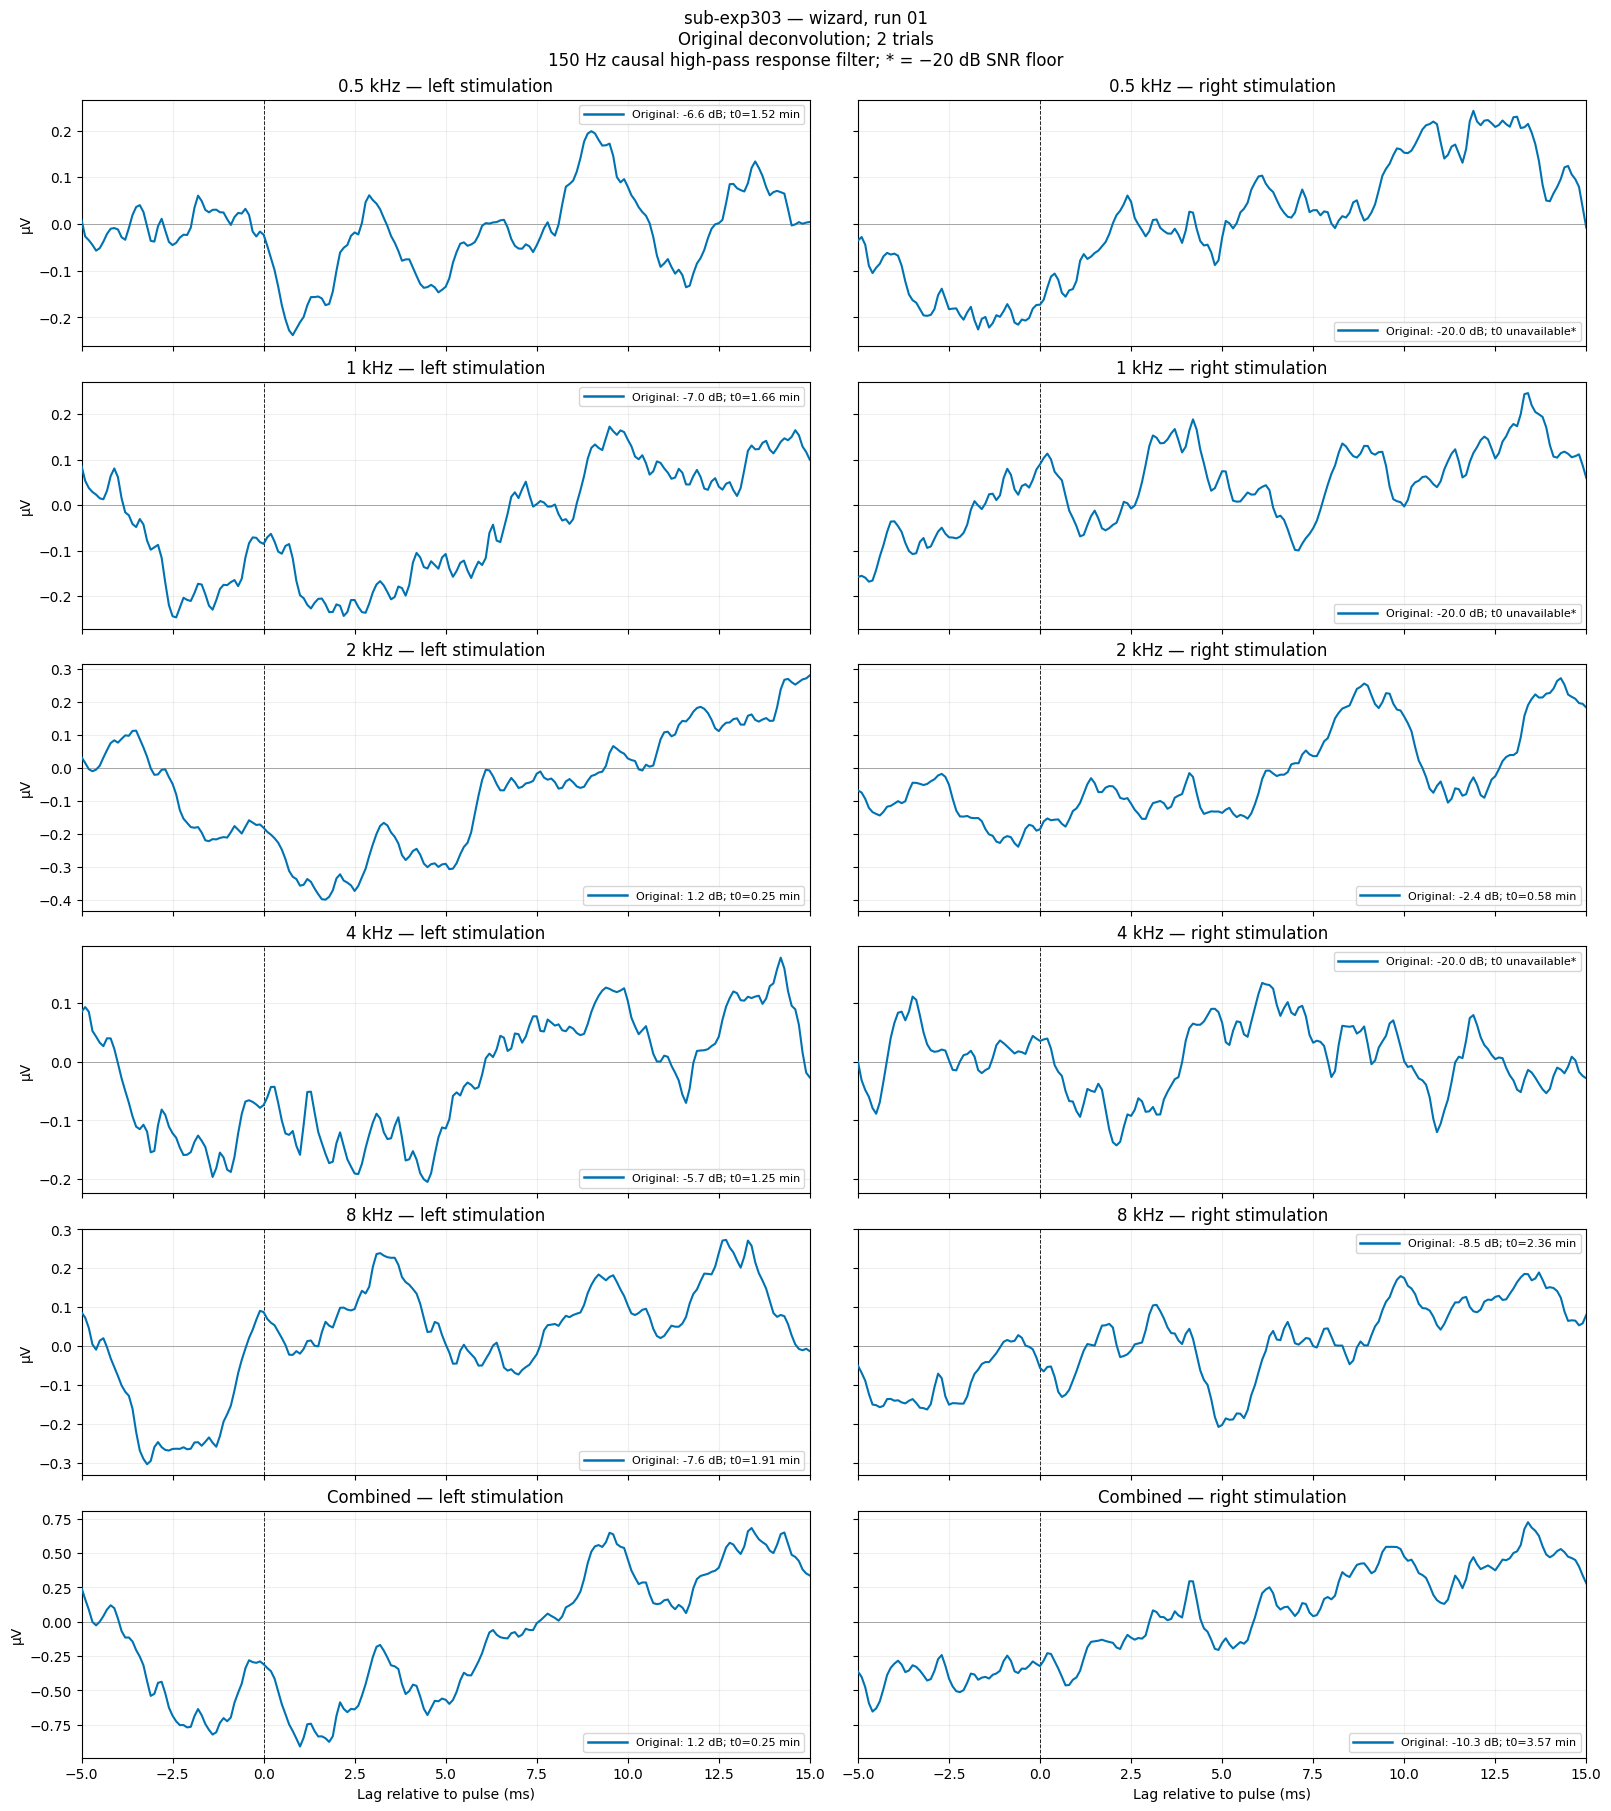

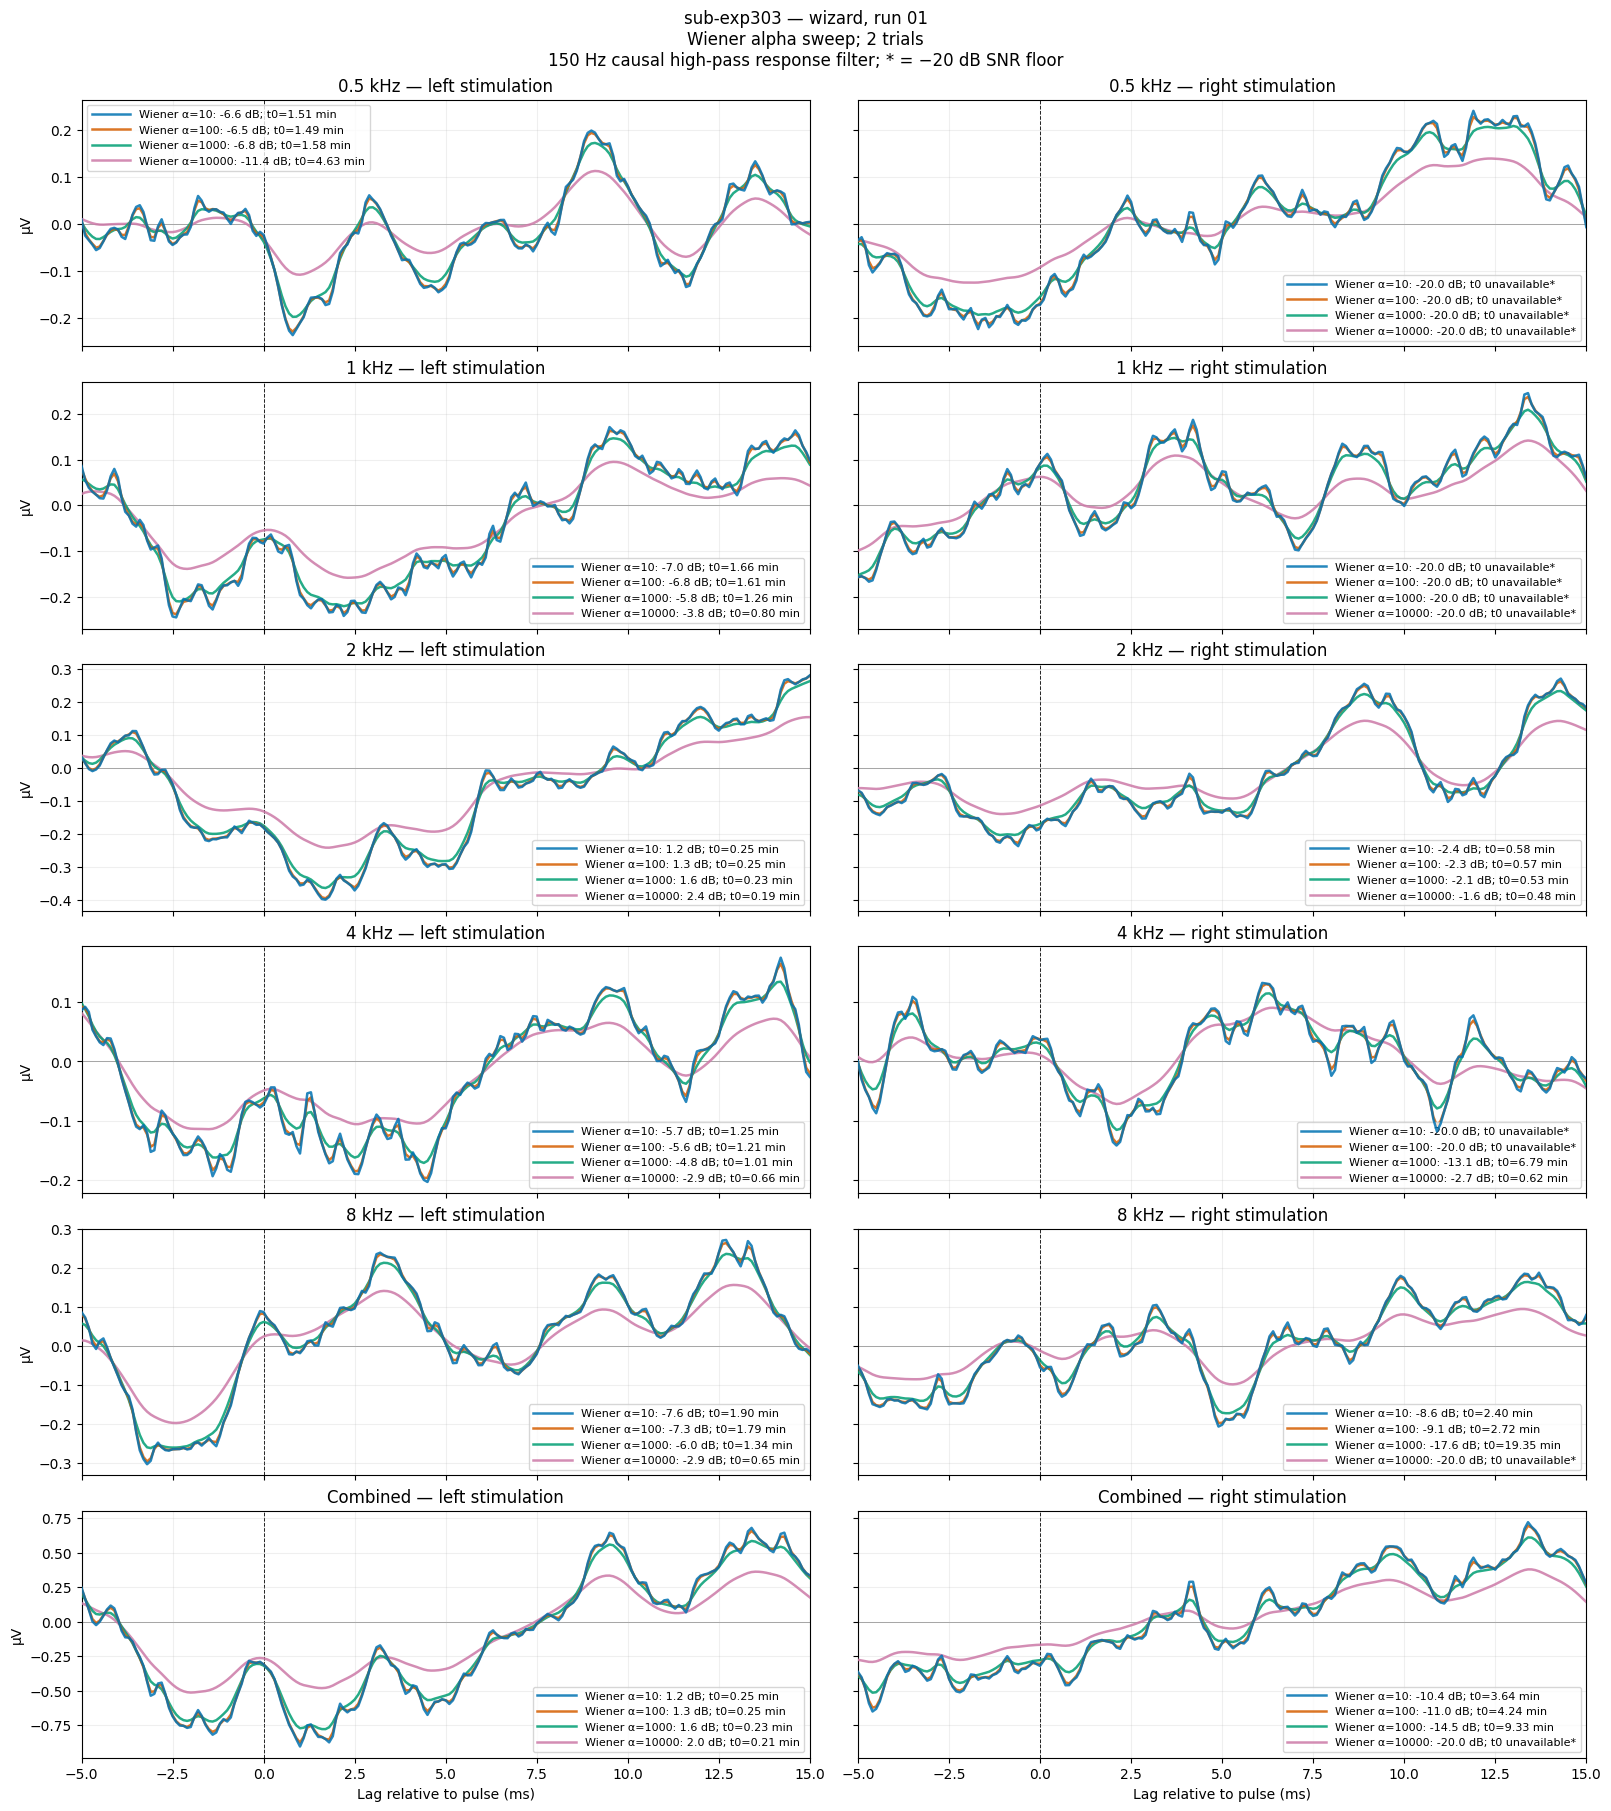

In [7]:
from matplotlib.lines import Line2D

def plot_methods(result, method_names, title, sweep=False):
    lags_ms = (
        np.arange(-analysis.n_pre, analysis.n_post)
        / result["fs"] * 1000
    )
    show = (lags_ms >= -5) & (lags_ms <= 15)

    fig, axes = plt.subplots(
        6, 2,
        figsize=(16, 18),
        sharex=True,
        sharey="row",
        constrained_layout=True,
    )

    # Distinct colors plus dash patterns for overlapping curves.
    colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
    styles = ["-", "--", "-.", ":"]
    method_styles = {
        name: {
            "color": colors[i % len(colors)],
            "linestyle": "-",
            "alpha": 0.85 if sweep else 1.0,
        }
        for i, name in enumerate(method_names)
    }

    for row in range(6):
        is_band = row < len(bands_khz)

        for ear, ear_name in enumerate(ears):
            ax = axes[row, ear]
            handles = []

            for i, name in enumerate(method_names):
                variant = result["variants"][name]

                if is_band:
                    curve = variant["band_curves"][ear, row]
                    snr = variant["band_snr"][ear, row]
                    t0 = variant["band_t0"][ear, row]
                else:
                    curve = variant["combined_curves"][ear]
                    snr = variant["combined_snr"][ear]
                    t0 = variant["combined_t0"][ear]

                style = method_styles[name]

                ax.plot(
                    lags_ms[show],
                    curve[show],
                    **style,
                    linewidth=1.8 if sweep else 1.5,
                    # Draw earlier methods above later ones.
                    zorder=len(method_names) - i + 2,
                )

                time_label = (
                    "t0 unavailable*"
                    if snr <= -20
                    else f"t0={t0 / 60:.2f} min"
                )

                # Explicit handles preserve the legend's method order.
                handles.append(Line2D(
                    [0], [0],
                    **style,
                    linewidth=1.8,
                    label=f"{name}: {snr:.1f} dB; {time_label}",
                ))

            panel = (
                f"{bands_khz[row]:g} kHz"
                if is_band else "Combined"
            )

            ax.set_title(f"{panel} — {ear_name} stimulation")
            ax.axvline(
                0, color="black", linestyle="--",
                linewidth=0.7, zorder=0,
            )
            ax.axhline(0, color="gray", linewidth=0.5, zorder=0)
            ax.set_xlim(-5, 15)
            ax.grid(alpha=0.2)
            ax.legend(handles=handles, fontsize=8, handlelength=3.5)

            if ear == 0:
                ax.set_ylabel("µV")

    for ax in axes[-1]:
        ax.set_xlabel("Lag relative to pulse (ms)")

    fig.suptitle(
        f"{result['subject']} — {stories[story_index]}, run {run}\n"
        f"{title}; {result['n_trials']} trials\n"
        "150 Hz causal high-pass response filter; "
        "* = −20 dB SNR floor"
    )

    plt.show()


for result in results:
    plot_methods(
        result,
        method_names=["Original"],
        title="Original deconvolution",
    )

    wiener_names = [
        f"Wiener α={alpha:g}"
        for alpha in alphas
    ]

    plot_methods(
        result,
        method_names=wiener_names,
        title="Wiener alpha sweep",
        sweep=True,
    )